In [43]:
import pandas as pd

In [98]:
!git add .
!git commit -m "Classification"
!git push -u origin main

[main 342b81d] Classification
 4 files changed, 2238 insertions(+)
 create mode 100644 Classification/.ipynb_checkpoints/heart-checkpoint.csv
 create mode 100644 Classification/.ipynb_checkpoints/heart_dieases-checkpoint.ipynb
 create mode 100644 Classification/heart.csv
 create mode 100644 Classification/heart_dieases.ipynb
Enumerating objects: 8, done.
Counting objects: 100% (8/8), done.
Delta compression using up to 10 threads
Compressing objects: 100% (7/7), done.
Writing objects: 100% (7/7), 739.72 KiB | 23.86 MiB/s, done.
Total 7 (delta 1), reused 0 (delta 0), pack-reused 0 (from 0)
remote: Resolving deltas: 100% (1/1), completed with 1 local object.
To https://github.com/pankajvshnv/Data-Science.git
   a6d031f..342b81d  main -> main
branch 'main' set up to track 'origin/main'.


In [44]:
data = pd.read_csv("heart.csv")

In [45]:
df = data

In [46]:
df.isnull().sum()

age         0
sex         0
cp          0
trtbps      0
chol        0
fbs         0
restecg     0
thalachh    0
exng        0
oldpeak     0
slp         0
caa         0
thall       0
output      0
dtype: int64

In [47]:
df[df.duplicated(keep = False)]

,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
163,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1
164,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1


In [48]:
df = df.drop_duplicates()

In [50]:
df = df.rename(columns={'cp': 'chest_pain'})

# Exploratory Data Analysis

In [57]:
df.info()

<class 'pandas.DataFrame'>
Index: 302 entries, 0 to 302
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   age         302 non-null    int64  
 1   sex         302 non-null    int64  
 2   chest_pain  302 non-null    int64  
 3   trtbps      302 non-null    int64  
 4   chol        302 non-null    int64  
 5   fbs         302 non-null    int64  
 6   restecg     302 non-null    int64  
 7   thalachh    302 non-null    int64  
 8   exng        302 non-null    int64  
 9   oldpeak     302 non-null    float64
 10  slp         302 non-null    int64  
 11  caa         302 non-null    int64  
 12  thall       302 non-null    int64  
 13  output      302 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 35.4 KB


In [58]:
df.describe()

,age,sex,chest_pain,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
count,302.00000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000
mean,54.42053,0.682119,0.963576,131.602649,246.500000,0.149007,0.526490,149.569536,0.327815,1.043046,1.397351,0.718543,2.314570,0.543046
std,9.04797,0.466426,1.032044,17.563394,51.753489,0.356686,0.526027,22.903527,0.470196,1.161452,0.616274,1.006748,0.613026,0.498970
min,29.00000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.00000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.250000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.50000,1.000000,1.000000,130.000000,240.500000,0.000000,1.000000,152.500000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.00000,1.000000,2.000000,140.000000,274.750000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.00000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [59]:
df.head()

,age,sex,chest_pain,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [61]:
df['output'].value_counts()

output
1    164
0    138
Name: count, dtype: int64

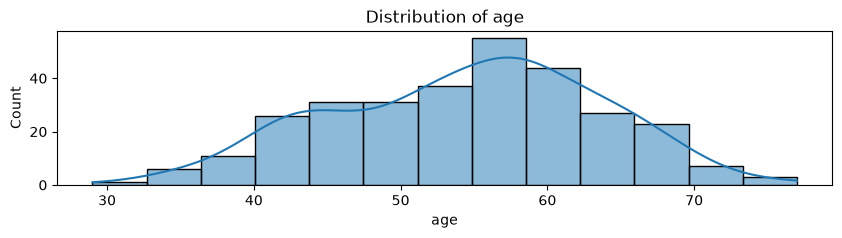

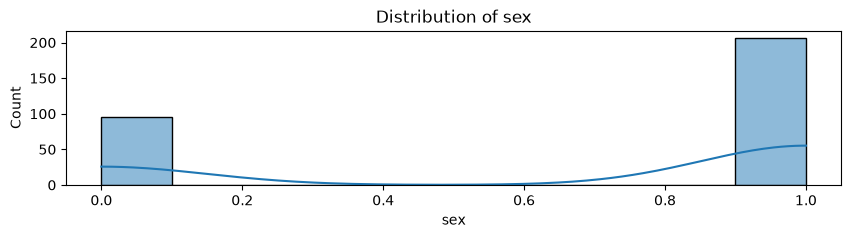

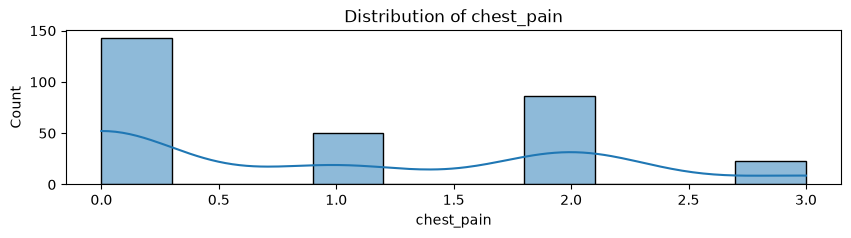

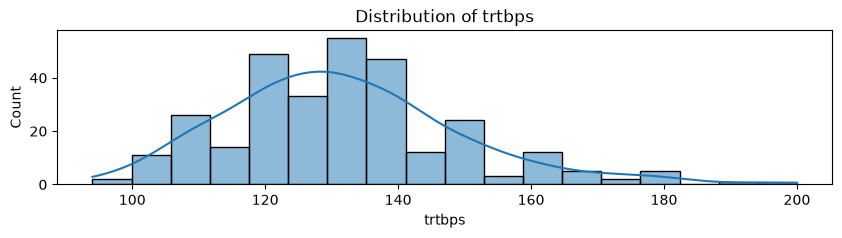

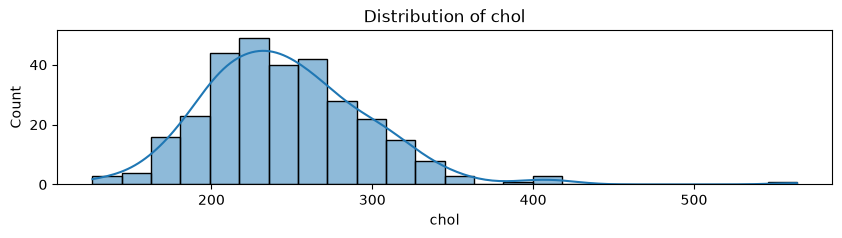

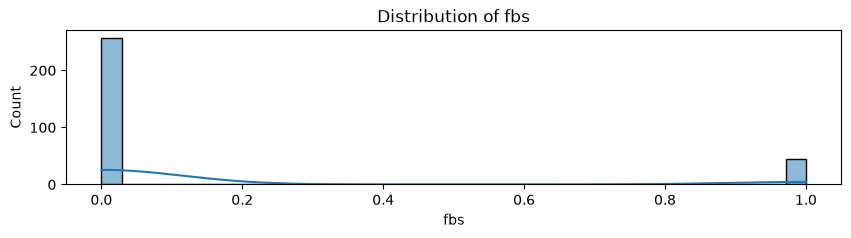

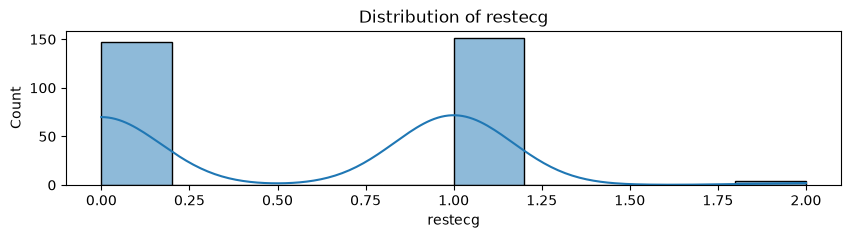

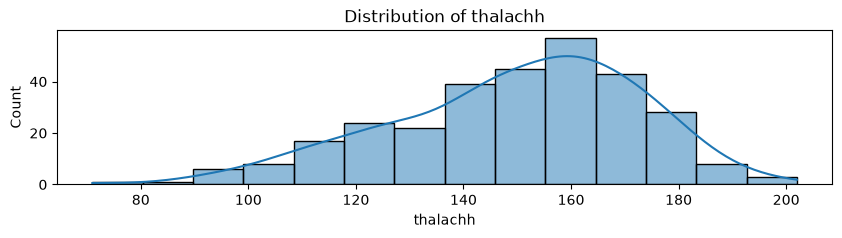

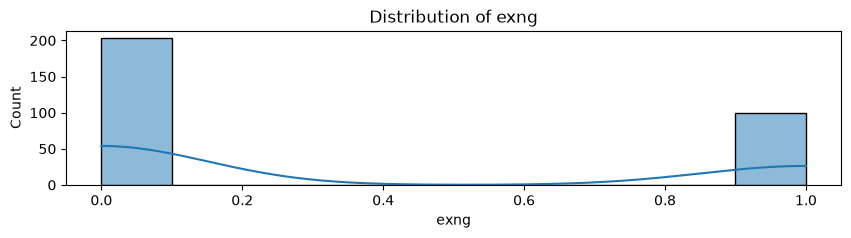

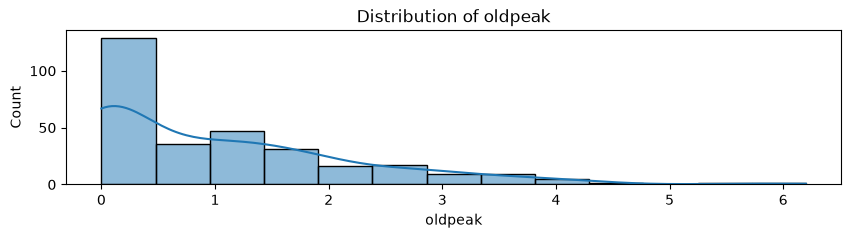

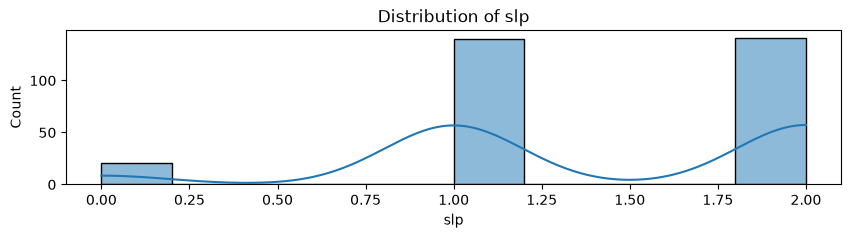

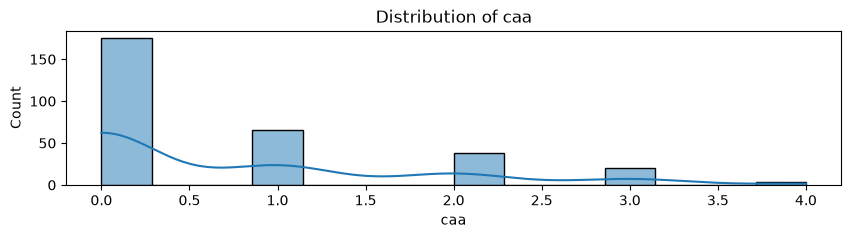

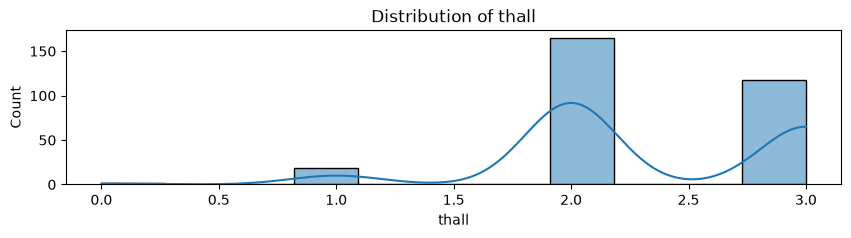

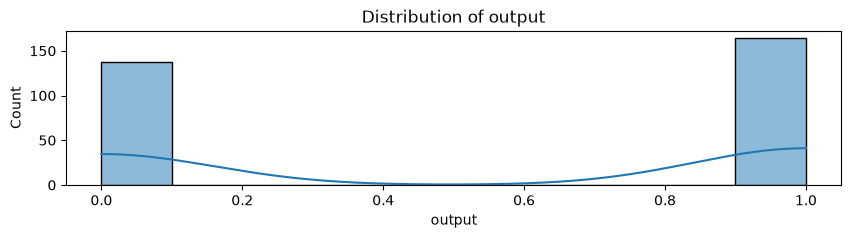

In [75]:
import matplotlib.pyplot as plt
import seaborn as sns

for i in df.columns:
    plt.figure(figsize=(10,2))
    sns.histplot(data=df, x=i, kde=True)
    plt.title(f"Distribution of {i}")
    plt.show()

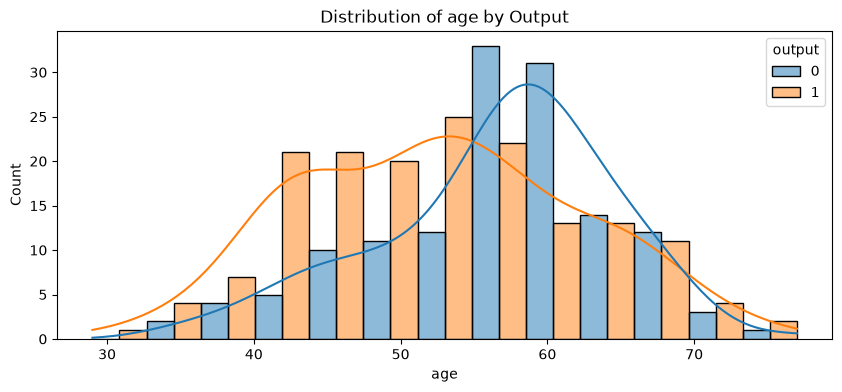

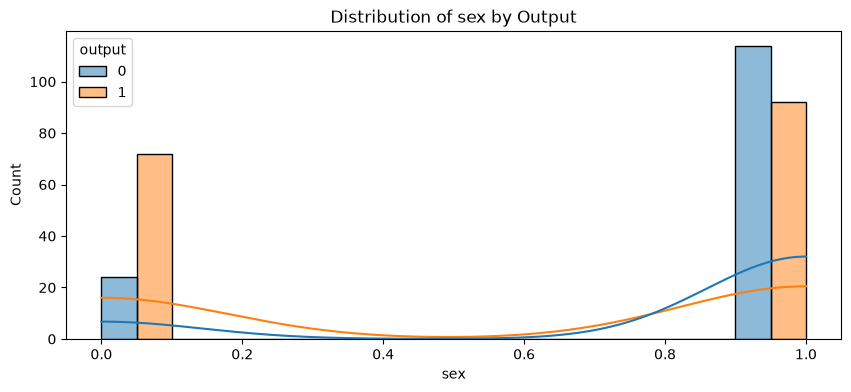

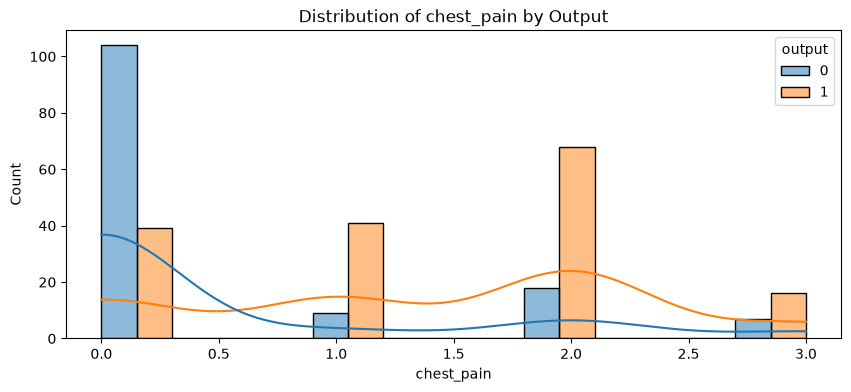

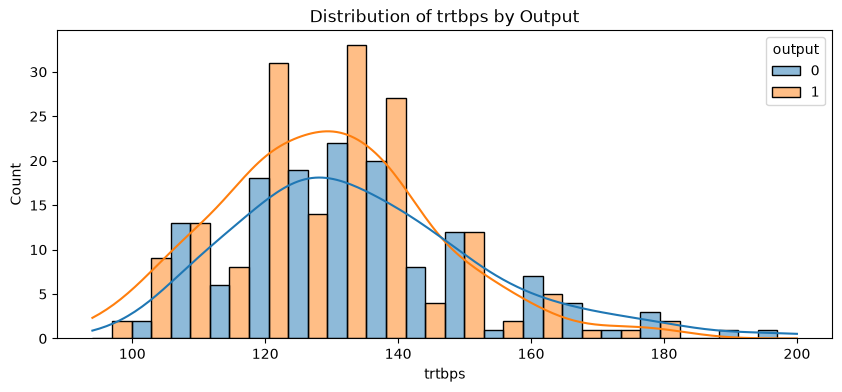

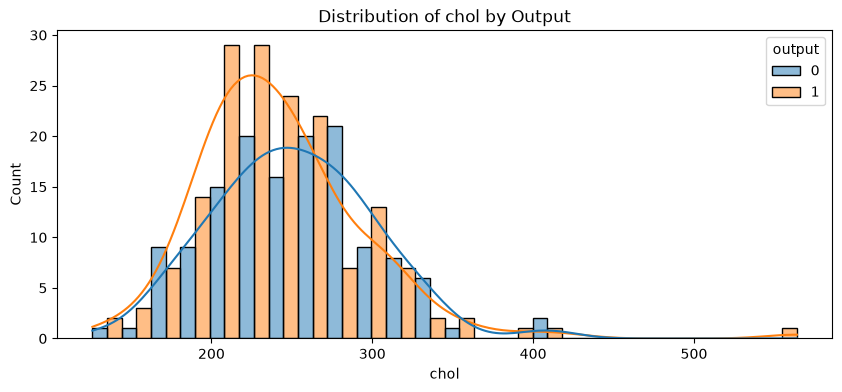

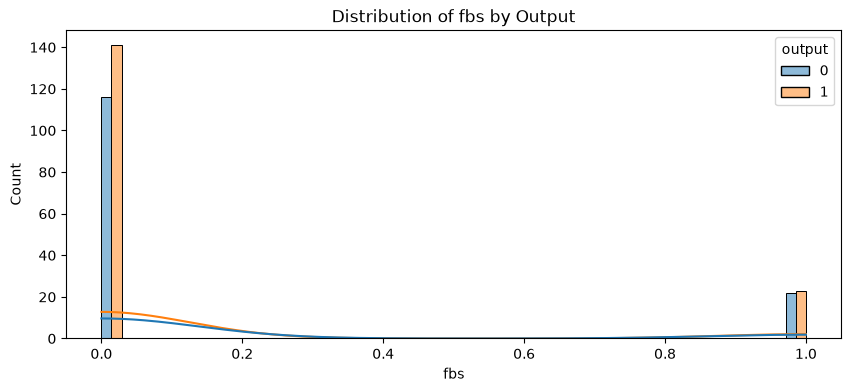

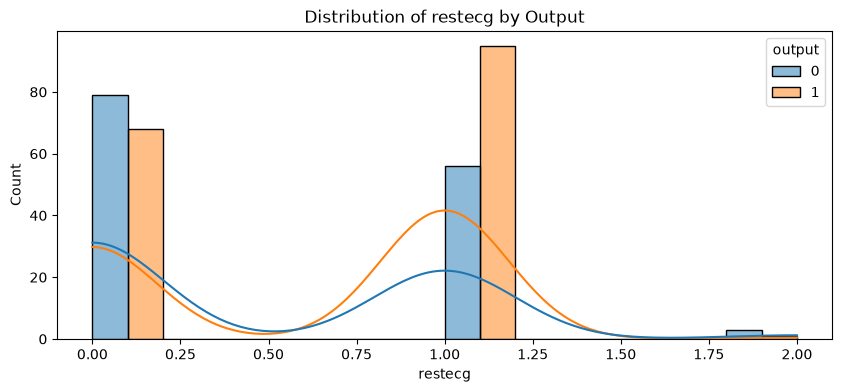

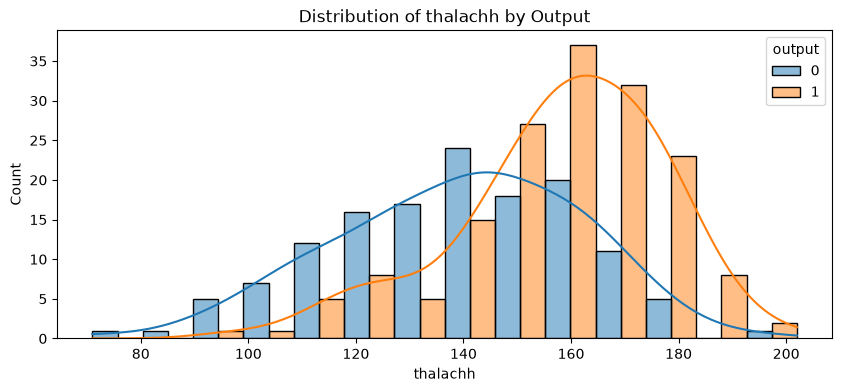

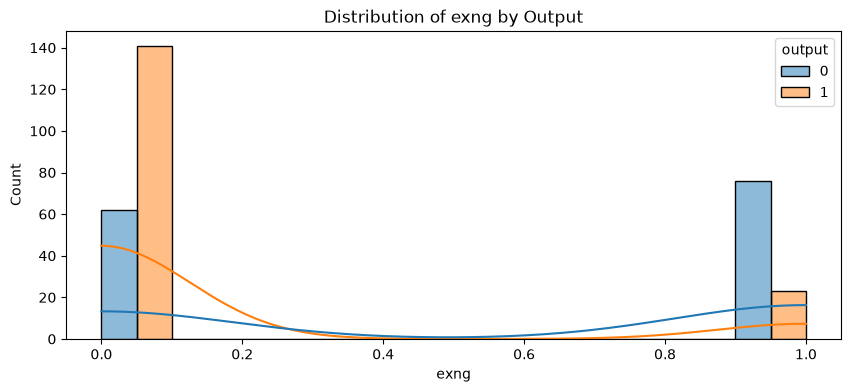

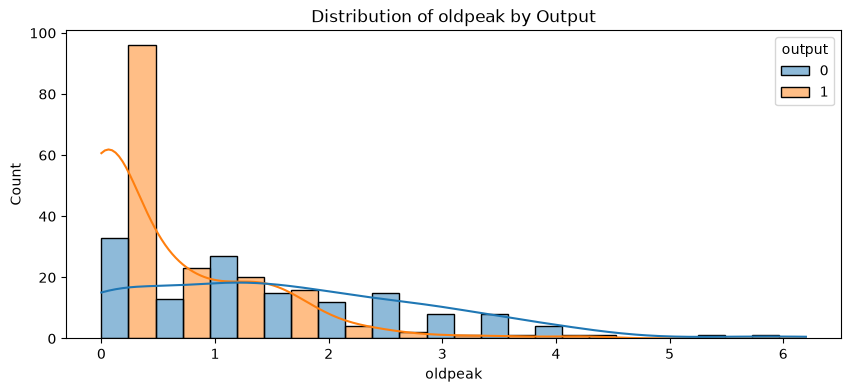

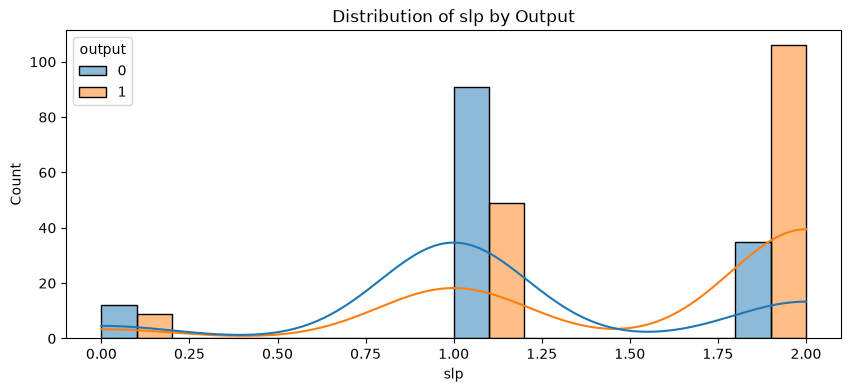

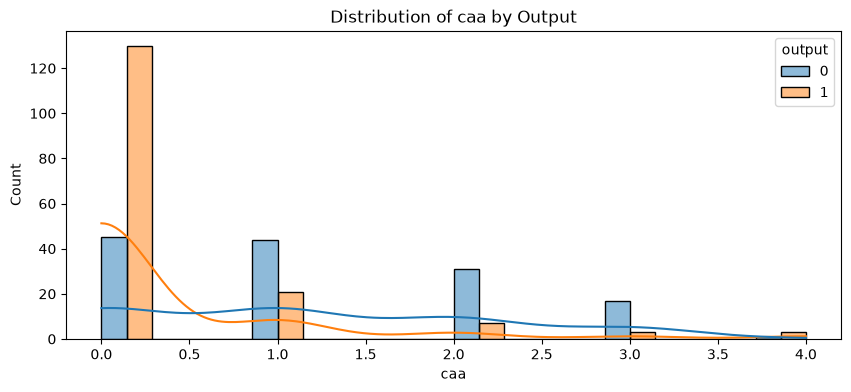

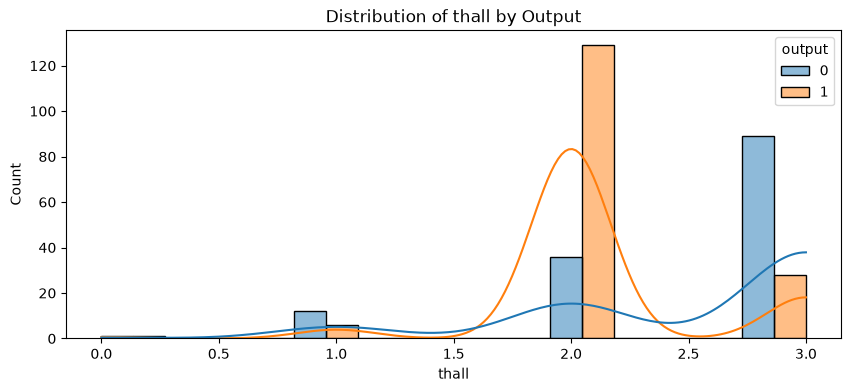

In [81]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in df.columns:
    if col != 'output':
        plt.figure(figsize=(10, 4))
        sns.histplot(data=df, x=col, hue='output', kde=True, multiple='dodge')
        plt.title(f"Distribution of {col} by Output")
        plt.show()

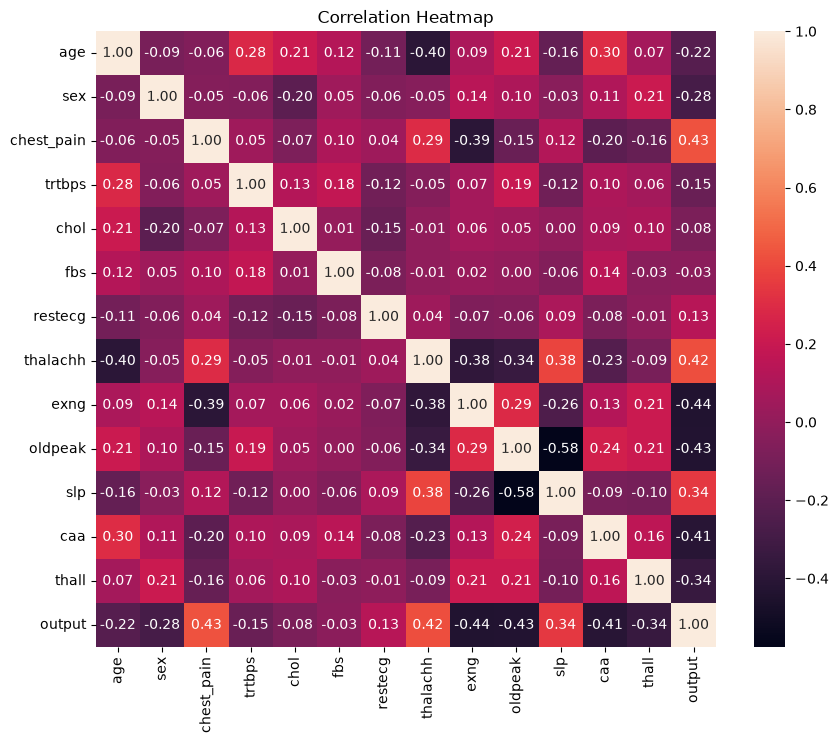

In [97]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

# Data preprocessing and cleaning

In [ ]:
df = 

In [ ]:
import matplotlib.pyplot 